# LAB_ASSIGNMENT_03 — Young's Double-Slit Experiment



In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sound_speed = 1481.0
frequency = 1.00e6
source_separation = 0.010
observation_distance = 0.600
source_strength = 1.00

wavelength = sound_speed / frequency
wave_number = 2.0 * np.pi / wavelength
grid_spacing = 0.0005
fringe_spacing = wavelength * observation_distance / source_separation

x = np.arange(grid_spacing, observation_distance + grid_spacing / 2, grid_spacing)
y = np.arange(-0.075, 0.075 + grid_spacing / 2, grid_spacing)
X, Y = np.meshgrid(x, y)
source_y_positions = np.array([source_separation / 2, -source_separation / 2])

r1 = np.sqrt(X**2 + (Y - source_y_positions[0]) ** 2)
r2 = np.sqrt(X**2 + (Y - source_y_positions[1]) ** 2)

wave_1 = source_strength * np.exp(1j * wave_number * r1) / r1
wave_2 = source_strength * np.exp(1j * wave_number * r2) / r2
wavefield = wave_1 + wave_2
amplitude = np.abs(wavefield)
real_part = np.real(wavefield)

observation_index = int(np.argmin(np.abs(x - observation_distance)))
numerical_profile = amplitude[:, observation_index]

print(f"Water sound speed:       {sound_speed:.1f} m/s")
print(f"Frequency:               {frequency / 1e6:.2f} MHz")
print(f"Wavelength:              {wavelength * 1e3:.3f} mm")
print(f"Wave number:             {wave_number:.2f} rad/m")
print(f"Source separation:       {source_separation * 1e3:.1f} mm")
print(f"Observation distance:    {x[observation_index]:.3f} m")
print(f"Far-field fringe spacing:{fringe_spacing * 1e2: .2f} cm")
print(f"Grid spacing:            {grid_spacing * 1e3:.2f} mm")
print(f"Wavefield array shape:   {wavefield.shape}")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "#fbfcfe",
    "axes.edgecolor": "#52616b",
    "axes.linewidth": 0.8,
    "grid.color": "#cbd5df",
    "grid.alpha": 0.55,
})

def add_student_header(figure):
    figure.text(0.5, 0.965, "Student: NIKUL PRAJAPATI", ha="center", va="top",
                fontsize=16, fontweight="bold", color="#18324a")
    figure.text(0.5, 0.923,
                "University: Technische Hochschule Deggendorf (THD)  |  Semester: WS-26/27",
                ha="center", va="top", fontsize=9, color="#34495e")
    figure.text(0.5, 0.895,
                "Course: Special Topic of Contactless Sensors Systems (WS26/27)",
                ha="center", va="top", fontsize=9, color="#34495e")
    figure.text(0.5, 0.867,
                "Assignment: LAB_ASSIGNMENT_03  |  Title: Young's Double-Slit Experiment",
                ha="center", va="top", fontsize=9, color="#34495e")
    figure.add_artist(plt.Line2D([0.08, 0.92], [0.835, 0.835],
                                 transform=figure.transFigure, color="#cbd5df", linewidth=0.8))

Water sound speed:       1481.0 m/s
Frequency:               1.00 MHz
Wavelength:              1.481 mm
Wave number:             4242.53 rad/m
Source separation:       10.0 mm
Observation distance:    0.600 m
Far-field fringe spacing: 8.89 cm
Grid spacing:            0.50 mm
Wavefield array shape:   (301, 1200)


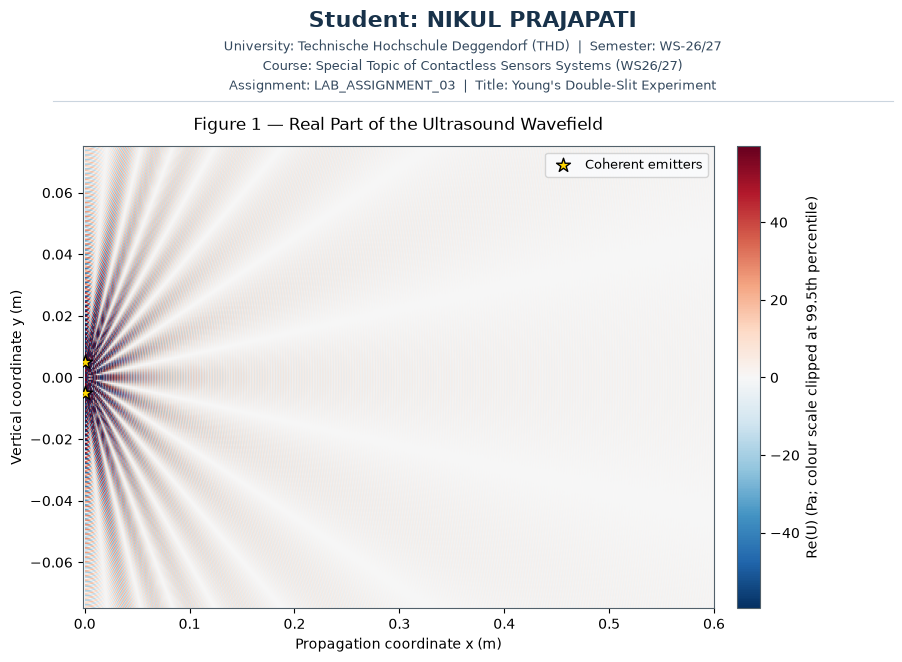

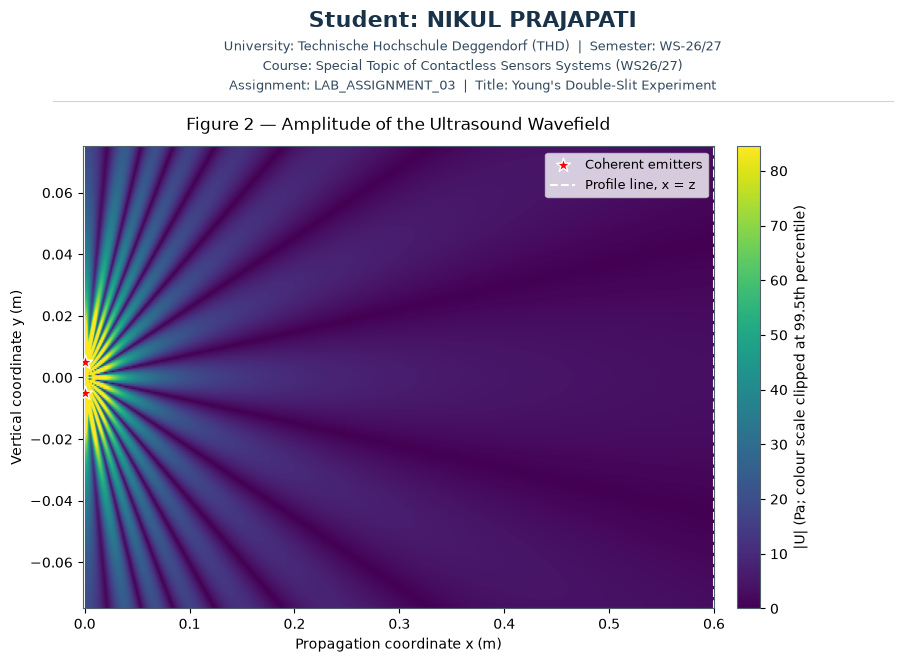

In [14]:
figure_directory = Path("figures")
figure_directory.mkdir(parents=True, exist_ok=True)

extent = [x[0], x[-1], y[0], y[-1]]
real_limit = np.percentile(np.abs(real_part), 99.5)
amplitude_limit = np.percentile(amplitude, 99.5)

fig, ax = plt.subplots(figsize=(10, 7))
add_student_header(fig)
fig.subplots_adjust(left=0.11, right=0.88, bottom=0.11, top=0.77)
image = ax.imshow(
    real_part,
    origin="lower",
    extent=extent,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-real_limit,
    vmax=real_limit,
)
ax.scatter(
    [0, 0], source_y_positions, marker="*", s=110, color="gold",
    edgecolor="black", label="Coherent emitters", zorder=3,
)
ax.set_xlim(-0.002, x[-1])
ax.set_xlabel("Propagation coordinate x (m)")
ax.set_ylabel("Vertical coordinate y (m)")
ax.set_title("Figure 1 — Real Part of the Ultrasound Wavefield", pad=12)
ax.legend(loc="upper right")
fig.colorbar(image, ax=ax, label="Re(U) (Pa; colour scale clipped at 99.5th percentile)", pad=0.03)
fig.savefig(figure_directory / "01_real_part.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 7))
add_student_header(fig)
fig.subplots_adjust(left=0.11, right=0.88, bottom=0.11, top=0.77)
image = ax.imshow(
    amplitude,
    origin="lower",
    extent=extent,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=amplitude_limit,
)
ax.scatter(
    [0, 0], source_y_positions, marker="*", s=110, color="red",
    edgecolor="white", label="Coherent emitters", zorder=3,
)
ax.axvline(observation_distance, color="white", linestyle="--", linewidth=1.5, label="Profile line, x = z")
ax.set_xlim(-0.002, x[-1])
ax.set_xlabel("Propagation coordinate x (m)")
ax.set_ylabel("Vertical coordinate y (m)")
ax.set_title("Figure 2 — Amplitude of the Ultrasound Wavefield", pad=12)
ax.legend(loc="upper right")
fig.colorbar(image, ax=ax, label="|U| (Pa; colour scale clipped at 99.5th percentile)", pad=0.03)
fig.savefig(figure_directory / "02_amplitude.png", dpi=300, bbox_inches="tight")
plt.show()

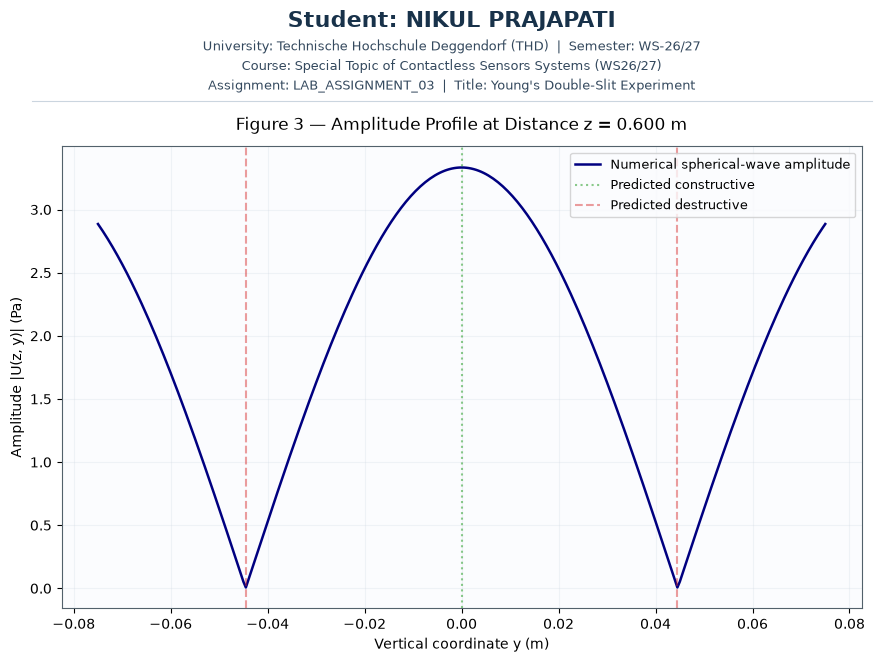

In [15]:
fig, ax = plt.subplots(figsize=(10, 7))
add_student_header(fig)
fig.subplots_adjust(left=0.11, right=0.91, bottom=0.11, top=0.77)
ax.plot(y, numerical_profile, color="navy", linewidth=1.8, label="Numerical spherical-wave amplitude")

first_order = int(np.ceil(y[0] / fringe_spacing))
last_order = int(np.floor(y[-1] / fringe_spacing))
for order in range(first_order, last_order + 1):
    position = order * fringe_spacing
    ax.axvline(position, color="tab:green", linestyle=":", alpha=0.55,
               label="Predicted constructive" if order == first_order else None)

first_dark_order = int(np.floor(y[0] / fringe_spacing - 0.5))
last_dark_order = int(np.ceil(y[-1] / fringe_spacing - 0.5))
dark_label_added = False
for order in range(first_dark_order, last_dark_order + 1):
    position = (order + 0.5) * fringe_spacing
    if y[0] <= position <= y[-1]:
        ax.axvline(position, color="tab:red", linestyle="--", alpha=0.45,
                   label="Predicted destructive" if not dark_label_added else None)
        dark_label_added = True

ax.set_xlabel("Vertical coordinate y (m)")
ax.set_ylabel("Amplitude |U(z, y)| (Pa)")
ax.set_title(f"Figure 3 — Amplitude Profile at Distance z = {x[observation_index]:.3f} m", pad=12)
ax.grid(True, alpha=0.25)
ax.legend()
fig.savefig(figure_directory / "03_amplitude_profile.png", dpi=300, bbox_inches="tight")
plt.show()

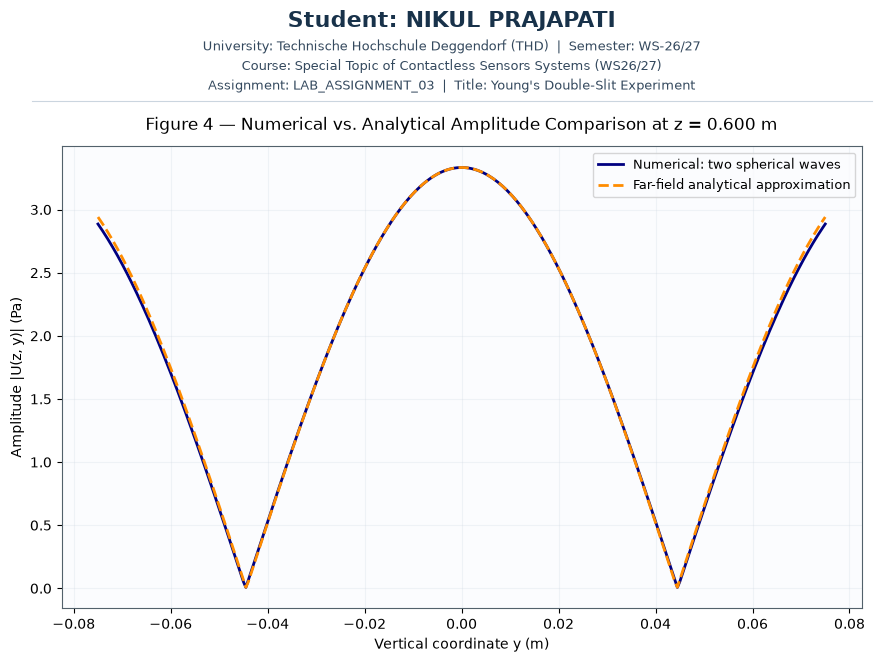

Far-field fringe spacing:                 0.08886 m (8.89 cm)
z / (d^2 / wavelength):                    8.89
Maximum observation angle in plotted area: 7.13 degrees
Normalized profile RMSE:                   0.0077 of numerical peak
Maximum normalized absolute error:         0.0166 of numerical peak
Saved figures: 01_real_part.png, 02_amplitude.png, 03_amplitude_profile.png, 04_far_field_comparison.png


In [16]:
analytical_profile = (
    2.0 * source_strength / observation_distance
    * np.abs(np.cos(np.pi * source_separation * y / (wavelength * observation_distance)))
)
profile_difference = numerical_profile - analytical_profile
normalized_rmse = np.sqrt(np.mean(profile_difference**2)) / np.max(numerical_profile)
maximum_normalized_error = np.max(np.abs(profile_difference)) / np.max(numerical_profile)

fig, ax = plt.subplots(figsize=(10, 7))
add_student_header(fig)
fig.subplots_adjust(left=0.11, right=0.91, bottom=0.11, top=0.77)
ax.plot(y, numerical_profile, color="navy", linewidth=2,
        label="Numerical: two spherical waves")
ax.plot(y, analytical_profile, color="darkorange", linestyle="--", linewidth=2,
        label="Far-field analytical approximation")
ax.set_xlabel("Vertical coordinate y (m)")
ax.set_ylabel("Amplitude |U(z, y)| (Pa)")
ax.set_title(f"Figure 4 — Numerical vs. Analytical Amplitude Comparison at z = {observation_distance:.3f} m", pad=12)
ax.grid(True, alpha=0.25)
ax.legend()
fig.savefig(figure_directory / "04_far_field_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Far-field fringe spacing:                 {fringe_spacing:.5f} m ({fringe_spacing * 100:.2f} cm)")
print(f"z / (d^2 / wavelength):                    {observation_distance / (source_separation**2 / wavelength):.2f}")
print(f"Maximum observation angle in plotted area: {np.degrees(np.arctan(np.max(np.abs(y)) / observation_distance)):.2f} degrees")
print(f"Normalized profile RMSE:                   {normalized_rmse:.4f} of numerical peak")
print(f"Maximum normalized absolute error:         {maximum_normalized_error:.4f} of numerical peak")
print("Saved figures:", ", ".join(sorted(path.name for path in figure_directory.glob("*.png"))))